# 06 — Model Evaluation & Business Insights

## Objective
Evaluate all three models honestly, attribute the gain over the
premium baseline correctly, assess calibration by segment,
compute SHAP on the primary model, and derive actionable
underwriting recommendations.

## What We Know Coming In
  - All three models are tied on normalised Gini (0.743-0.745)
  - IDV + policy type alone scores 0.719: most of the gain over
    the premium (0.691) is a pricing correction, not discovery
  - Frequency is at its ceiling (0.675 vs oracle 0.679)
  - Severity is the hard part: 17% deviance explained, Spearman 0.45
  - Missing-age artifact affects 2% of rows (IDV inflated 1.55x)
  - 2% of policies with NCB imputed by a business rule, not data

## This Notebook Answers
  1. Does the gain hold on the artifact-free rows?
  2. Which segments does the model price better than the premium?
  3. What does SHAP say about individual predictions?
  4. Is the model well-calibrated across risk tiers?
  5. What is the business value of better pricing?
  6. What should the README limitations list contain?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import shap
import pickle
import json
import os
import warnings
warnings.filterwarnings("ignore")
from sklearn.metrics import mean_tweedie_deviance, roc_auc_score

PROCESSED = "../data/processed"
SEED      = 42
Y_SCALE   = 1000.0
P_FINAL   = 1.67

spec    = json.load(open(f"{PROCESSED}/feature_spec.json"))
FEATURES = spec["feature_cols"]
summary = json.load(open(f"{PROCESSED}/model_summary.json"))

with open(f"{PROCESSED}/models.pkl", "rb") as f:
    mdl = pickle.load(f)
gbm, glm, clf, sev = mdl["gbm"], mdl["glm"], mdl["freq"], mdl["sev"]

test  = pd.read_csv(f"{PROCESSED}/test_predictions.csv")
split = pd.read_csv(f"{PROCESSED}/split.csv")
model = pd.read_csv(f"{PROCESSED}/modeling_data.csv")

# Pull artifact flags into model (they weren't saved in NB04)
link = pd.read_csv(f"{PROCESSED}/policies_clean.csv",
                   usecols=["policy_id","policyholder_id"])
veh  = pd.read_csv(f"{PROCESSED}/vehicles_clean.csv",
                   usecols=["policyholder_id","vehicle_age_missing"])
ph   = pd.read_csv(f"{PROCESSED}/policyholders_clean.csv",
                   usecols=["policyholder_id","ncb_missing"])
model = (model.merge(link, on="policy_id", validate="1:1")
              .merge(veh,  on="policyholder_id", validate="1:1")
              .merge(ph,   on="policyholder_id", validate="1:1")
              .merge(pd.read_csv(f"{PROCESSED}/baseline_premium.csv"),
                     on="policy_id", validate="1:1"))

# Metrics (same as NB05)
def lorenz(actual, score):
    a, s = np.asarray(actual, float), np.asarray(score, float)
    g = pd.DataFrame({"a": a, "s": s}).groupby("s", sort=True)["a"].agg(["sum","size"])
    x = np.concatenate([[0.0], g["size"].cumsum().to_numpy() / len(a)])
    y = np.concatenate([[0.0], g["sum"].cumsum().to_numpy()  / a.sum()])
    return x, y

def gini(actual, score):
    x, y = lorenz(actual, score)
    return 1 - 2 * np.sum((x[1:]-x[:-1]) * (y[1:]+y[:-1]) / 2)

def norm_gini(actual, score):
    return gini(actual, score) / gini(actual, actual)

def dev(y, mu):
    return mean_tweedie_deviance(
        np.asarray(y) / Y_SCALE,
        np.maximum(np.asarray(mu), 1e-6) / Y_SCALE,
        power=P_FINAL)

def capture(actual, score, top=0.2, seed=0):
    a, s = np.asarray(actual, float), np.asarray(score, float)
    tie   = np.random.default_rng(seed).random(len(s))
    order = np.lexsort((tie, -s))
    return a[order[:int(len(a)*top)]].sum() / a.sum()

print("Loaded ✅")
print(f"  test rows          : {len(test):,}")
print(f"  full model rows    : {len(model):,}")
n_clean = ((model["vehicle_age_missing"]==0) & (model["ncb_missing"]==0)).sum()
print(f"  artifact-free rows : {n_clean:,} "
      f"({n_clean/len(model)*100:.1f}% of all policies)")

y_te   = test["claim_amount"].to_numpy()
f_te   = test["has_claim"].to_numpy()
idv_te = test["idv"].to_numpy()

PREDS = {
    "Premium (scaled)": None,  # computed below after we have k
    "IDV only (scaled)": None,
    "Tweedie GLM"       : test["pred_glm"].to_numpy(),
    "Tweedie LightGBM"  : test["pred_gbm"].to_numpy(),
    "Two-part LightGBM" : test["pred_two_part"].to_numpy(),
}
k_prem = (model.merge(split, on="policy_id")
               .query("set=='train'")["claim_amount"].sum()
          / model.merge(split, on="policy_id")
                 .query("set=='train'")["total_premium"].sum())
k_idv  = (model.merge(split, on="policy_id")
               .query("set=='train'")["claim_amount"].sum()
          / model.merge(split, on="policy_id")
                 .query("set=='train'")["idv"].sum())
PREDS["Premium (scaled)"]  = k_prem * test["total_premium"].to_numpy()
PREDS["IDV only (scaled)"] = k_idv  * idv_te

c:\Users\dsp96\Desktop\realworld-ds-ml\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loaded ✅
  test rows          : 19,596
  full model rows    : 97,978
  artifact-free rows : 94,073 (96.0% of all policies)


In [2]:
print("SECTION 1 — SCOREBOARD ON ARTIFACT-FREE TEST ROWS\n")
print("""
2% of policies have a missing vehicle age, which inflated their IDV
by 1.55x (NB05 Cell 2). Another 2% had NCB imputed by a business rule.
If those rows drive the results, the headline numbers are misleading.
We check by running the same scoreboard on the subset where both flags
are zero — the rows closest to what real data would look like.
""")

af_mask = (
    (test["vehicle_age_missing"] == 0) &
    (test["ncb_missing"] == 0)
)
y_af  = y_te[af_mask.to_numpy()]
print(f"Artifact-free test rows : {af_mask.sum():,} of {len(y_te):,}")
print(f"  claim rate : {f_te[af_mask.to_numpy()].mean()*100:.2f}%")
print(f"  total cost : ₹{y_af.sum()/1e6:.1f}M")

rows_all, rows_af = [], []
for nm, s in PREDS.items():
    s_af = s[af_mask.to_numpy()]
    rows_all.append(dict(model=nm, norm_gini=norm_gini(y_te,s),
                         deviance=dev(y_te,s), cap20=capture(y_te,s)))
    rows_af.append(dict(model=nm, norm_gini=norm_gini(y_af,s_af),
                        deviance=dev(y_af,s_af), cap20=capture(y_af,s_af)))

all_df = pd.DataFrame(rows_all)
af_df  = pd.DataFrame(rows_af)

print(f"\n{'Model':<25} {'All rows':>12} {'Artif-free':>12} {'Δ':>8}")
print(f"{'':25} {'Norm Gini':>12} {'Norm Gini':>12}")
print("-" * 62)
for a, b in zip(rows_all, rows_af):
    d = b["norm_gini"] - a["norm_gini"]
    print(f"  {a['model']:<23} {a['norm_gini']:>12.4f} "
          f"{b['norm_gini']:>12.4f} {d:>+8.4f}")

print("""
If Δ is small (< 0.005 in absolute terms) for all models,
the artifact rows are not driving the results. The gain
over the premium holds on clean data too.
If the models' Δ is larger than the premium's Δ, the artifacts
benefit the models more than the baseline.
""")

SECTION 1 — SCOREBOARD ON ARTIFACT-FREE TEST ROWS


2% of policies have a missing vehicle age, which inflated their IDV
by 1.55x (NB05 Cell 2). Another 2% had NCB imputed by a business rule.
If those rows drive the results, the headline numbers are misleading.
We check by running the same scoreboard on the subset where both flags
are zero — the rows closest to what real data would look like.

Artifact-free test rows : 18,783 of 19,596
  claim rate : 36.21%
  total cost : ₹1565.3M

Model                         All rows   Artif-free        Δ
                             Norm Gini    Norm Gini
--------------------------------------------------------------
  Premium (scaled)              0.6913       0.6950  +0.0037
  IDV only (scaled)             0.6727       0.6756  +0.0029
  Tweedie GLM                   0.7443       0.7480  +0.0036
  Tweedie LightGBM              0.7428       0.7462  +0.0034
  Two-part LightGBM             0.7449       0.7482  +0.0033

If Δ is small (< 0.005 in absolu

SECTION 2 — WHERE DOES THE GAIN OVER THE PREMIUM COME FROM?


From NB05:
  Premium (scaled)   : 0.6913
  IDV only (scaled)  : 0.6727
  IDV + policy type  : 0.7193   (NB05 scratch test)
  Tweedie LightGBM   : 0.7428

The full model beats the premium by 0.0515.
IDV alone is actually worse than the premium (0.6727 vs 0.6913)
because premium adds policy type and vehicle segment on top of IDV.
The IDV + policy type combination reaches 0.7193.
Everything else adds 0.7428 - 0.7193 = 0.0235.

Decomposition of the gain over the premium:
  Total gain                       : +0.0515
  From IDV + policy-type fix       : +0.0280 (54% of total gain)
  From all remaining features      : +0.0235 (46% of total gain)

What the policy-type gain means in practice:
  The generator charges own-damage premium on third-party-only policies.
  Those policies have a rel LR of 0.33 (one-third the portfolio average).
  ML learned to assign them low expected cost. A correctly-written rating
  structure would achiev

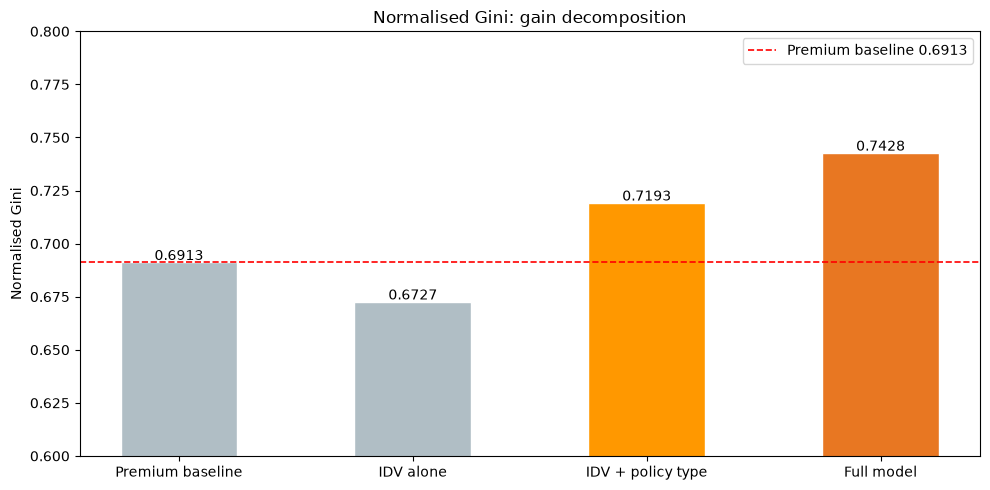

In [3]:
print("SECTION 2 — WHERE DOES THE GAIN OVER THE PREMIUM COME FROM?\n")
print("""
From NB05:
  Premium (scaled)   : 0.6913
  IDV only (scaled)  : 0.6727
  IDV + policy type  : 0.7193   (NB05 scratch test)
  Tweedie LightGBM   : 0.7428

The full model beats the premium by 0.0515.
IDV alone is actually worse than the premium (0.6727 vs 0.6913)
because premium adds policy type and vehicle segment on top of IDV.
The IDV + policy type combination reaches 0.7193.
Everything else adds 0.7428 - 0.7193 = 0.0235.
""")

gaps = {
    "Premium baseline"    : 0.6913,
    "IDV alone"           : 0.6727,
    "IDV + policy type"   : 0.7193,
    "Full model"          : 0.7428,
}
base = gaps["Premium baseline"]
full = gaps["Full model"]
step1 = gaps["IDV + policy type"] - base
step2 = full - gaps["IDV + policy type"]
total = full - base

print(f"Decomposition of the gain over the premium:")
print(f"  Total gain                       : {total:+.4f}")
print(f"  From IDV + policy-type fix       : {step1:+.4f} "
      f"({step1/total*100:.0f}% of total gain)")
print(f"  From all remaining features      : {step2:+.4f} "
      f"({step2/total*100:.0f}% of total gain)")
print()
print("""What the policy-type gain means in practice:
  The generator charges own-damage premium on third-party-only policies.
  Those policies have a rel LR of 0.33 (one-third the portfolio average).
  ML learned to assign them low expected cost. A correctly-written rating
  structure would achieve the same thing with a single underwriting rule.
  This is typical of real ML applications in insurance: the model finds
  systematic pricing errors that should have been caught by actuaries.
""")

# Visualise
fig, ax = plt.subplots(figsize=(10, 5))
names  = list(gaps.keys())
values = list(gaps.values())
colors = ["#B0BEC5","#B0BEC5","#FF9800","#E87722"]
bars   = ax.bar(names, values, color=colors, edgecolor="white", width=0.5)
ax.set_ylim(0.60, 0.80)
ax.axhline(base, color="red", linestyle="--", linewidth=1.2,
           label=f"Premium baseline {base:.4f}")
ax.set_title("Normalised Gini: gain decomposition")
ax.set_ylabel("Normalised Gini")
ax.legend()
for bar, v in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width()/2, v + 0.001,
            f"{v:.4f}", ha="center", fontsize=10)
plt.tight_layout()
plt.savefig(f"{PROCESSED}/eval_01_gain_attribution.png",
            dpi=130, bbox_inches="tight")
plt.show()

In [4]:
print("SECTION 3 — SEGMENT CALIBRATION\n")
print("""
Calibration means: when the model predicts ₹50K average cost for a group,
does the group actually cost ₹50K on average?
For an insurer, miscalibration by segment means systematic under- or
over-pricing of specific customer types, which competitors will exploit.
""")

seg_cols = {
    "vehicle_segment" : test.merge(
        pd.read_csv(f"{PROCESSED}/policies_clean.csv",
                    usecols=["policy_id","policyholder_id"]).merge(
        pd.read_csv(f"{PROCESSED}/vehicles_clean.csv",
                    usecols=["policyholder_id","vehicle_segment"]),
        on="policyholder_id"), on="policy_id")["vehicle_segment"].values,
    "policy_type"     : test.merge(
        pd.read_csv(f"{PROCESSED}/policies_clean.csv",
                    usecols=["policy_id","policy_type"]),
        on="policy_id")["policy_type"].values,
    "city_tier"       : test.merge(
        pd.read_csv(f"{PROCESSED}/policies_clean.csv",
                    usecols=["policy_id","policyholder_id"]).merge(
        pd.read_csv(f"{PROCESSED}/policyholders_clean.csv",
                    usecols=["policyholder_id","city_tier"]),
        on="policyholder_id"), on="policy_id")["city_tier"].values,
}

PRIMARY = "pred_gbm"

for dim, groups in seg_cols.items():
    print(f"── {dim} ──────────────────────────────────────────────")
    rows = []
    for g in sorted(set(groups)):
        m = groups == g
        if m.sum() < 100:
            continue
        a    = y_te[m]
        prem = PREDS["Premium (scaled)"][m]
        pred = PREDS["Tweedie LightGBM"][m]
        rows.append(dict(
            segment=g,
            n=m.sum(),
            actual_mean=a.mean(),
            model_mean=pred.mean(),
            prem_mean=prem.mean(),
            model_ratio=pred.mean() / a.mean(),
            prem_ratio=prem.mean() / a.mean(),
            model_gini=norm_gini(a, pred),
            prem_gini=norm_gini(a, prem),
        ))
    df_seg = pd.DataFrame(rows)
    print(f"  {'Segment':<22} {'N':>7} {'Actual':>10} "
          f"{'Model':>10} {'Prem':>10} {'ModelRatio':>11} "
          f"{'PremRatio':>10} {'ΔGini':>8}")
    for _, r in df_seg.iterrows():
        flag = ("  <- model better" if r["model_gini"] > r["prem_gini"] + 0.01
                else "  <- premium better" if r["prem_gini"] > r["model_gini"] + 0.01
                else "")
        print(f"  {r['segment']:<22} {int(r['n']):>7,} "
              f"₹{r['actual_mean']:>8,.0f} "
              f"₹{r['model_mean']:>8,.0f} "
              f"₹{r['prem_mean']:>8,.0f} "
              f"{r['model_ratio']:>10.3f}x "
              f"{r['prem_ratio']:>9.3f}x "
              f"{r['model_gini']-r['prem_gini']:>+7.4f}"
              f"{flag}")
    print()

SECTION 3 — SEGMENT CALIBRATION


Calibration means: when the model predicts ₹50K average cost for a group,
does the group actually cost ₹50K on average?
For an insurer, miscalibration by segment means systematic under- or
over-pricing of specific customer types, which competitors will exploit.

── vehicle_segment ──────────────────────────────────────────────
  Segment                      N     Actual      Model       Prem  ModelRatio  PremRatio    ΔGini
  economy                 10,552 ₹  24,509 ₹  24,491 ₹  43,364      0.999x     1.769x +0.1831  <- model better
  luxury                   1,865 ₹ 495,521 ₹ 436,180 ₹ 295,857      0.880x     0.597x +0.0951  <- model better
  mid                      6,099 ₹  61,764 ₹  53,757 ₹  74,861      0.870x     1.212x +0.1301  <- model better
  premium                    692 ₹ 114,398 ₹  92,155 ₹ 111,006      0.806x     0.970x +0.1175  <- model better
  two_wheeler                388 ₹   1,671 ₹   1,794 ₹   5,372      1.074x     3.214x +0.1079  

SECTION 4 — SHAP ON THE PRIMARY MODEL (Tweedie LightGBM)

Computing SHAP values on 1,000 test policies — takes ~1 minute...

Top 15 features by mean |SHAP| (model output is log ₹/₹1,000):
  Rank  Feature                           Mean |SHAP|
----------------------------------------------------
  1     log_idv                                0.5424  ███████████████████████████████████████████
  2     has_od_cover                           0.5032  ████████████████████████████████████████
  3     policy_type_third_party_only           0.1514  ████████████
  4     prior_claims_count                     0.1482  ███████████
  5     engine_cc                              0.1148  █████████
  6     vehicle_segment_luxury                 0.1068  ████████
  7     ncb_percentage                         0.0981  ███████
  8     age                                    0.0935  ███████
  9     city_tier_Metro                        0.0849  ██████
  10    vehicle_age_years                      0.0812  ███

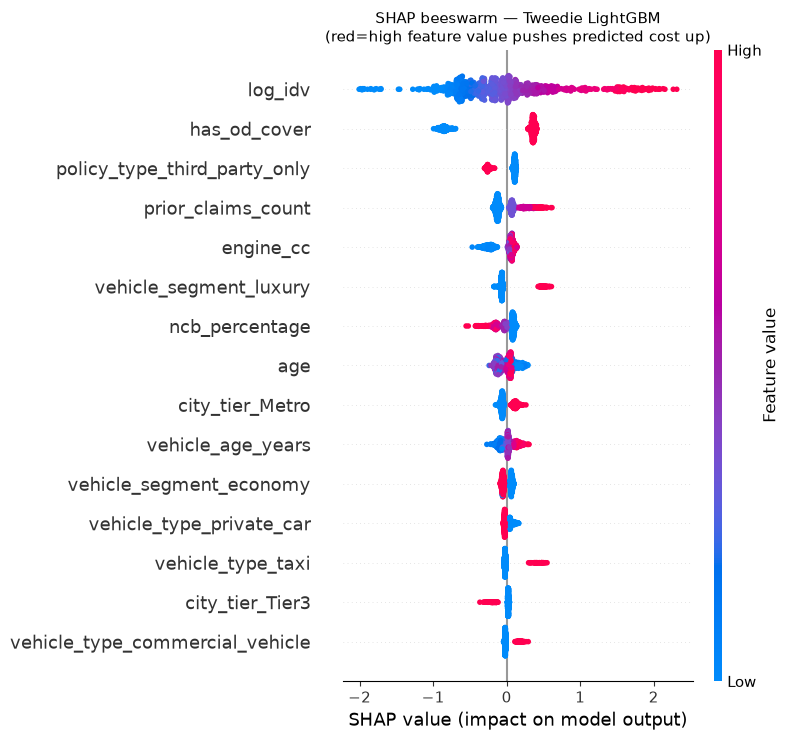

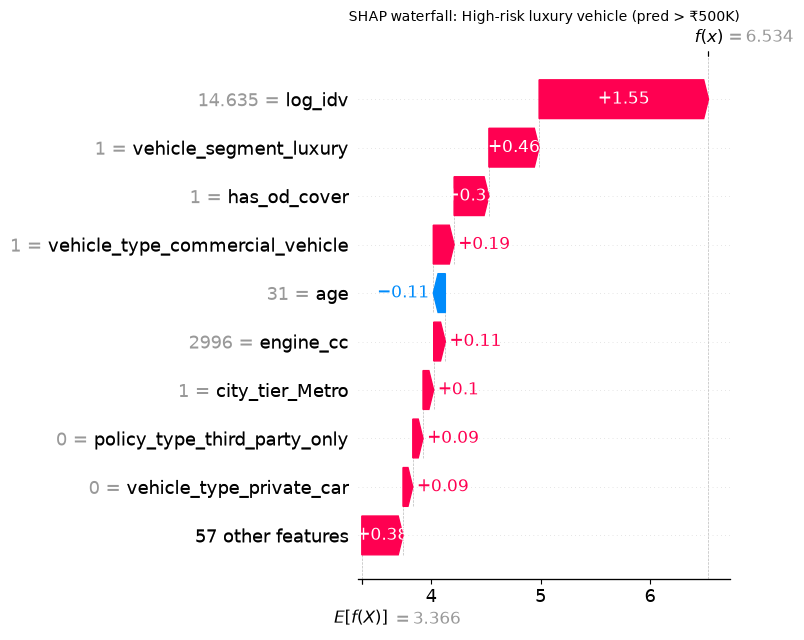

  High-risk luxury vehicle (pred > ₹500K): pred ₹688K  actual ₹0K


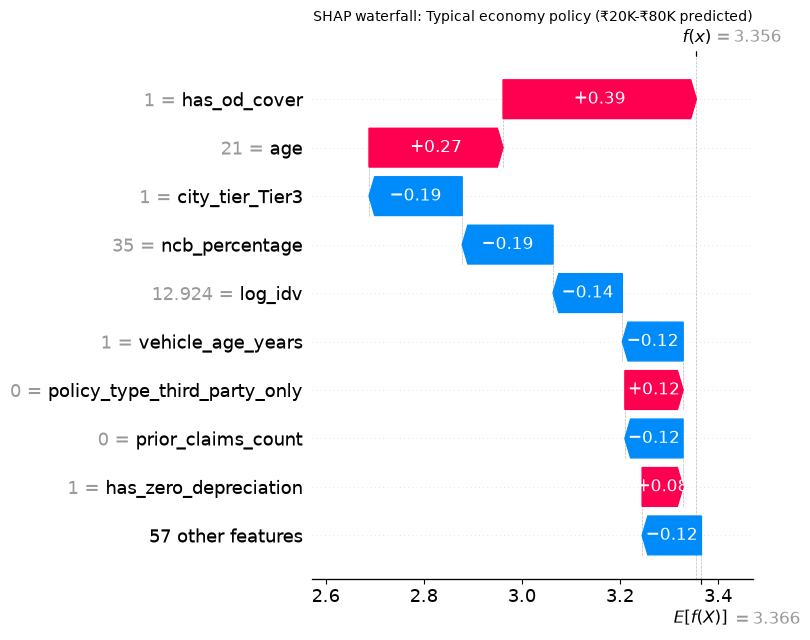

  Typical economy policy (₹20K-₹80K predicted): pred ₹29K  actual ₹0K


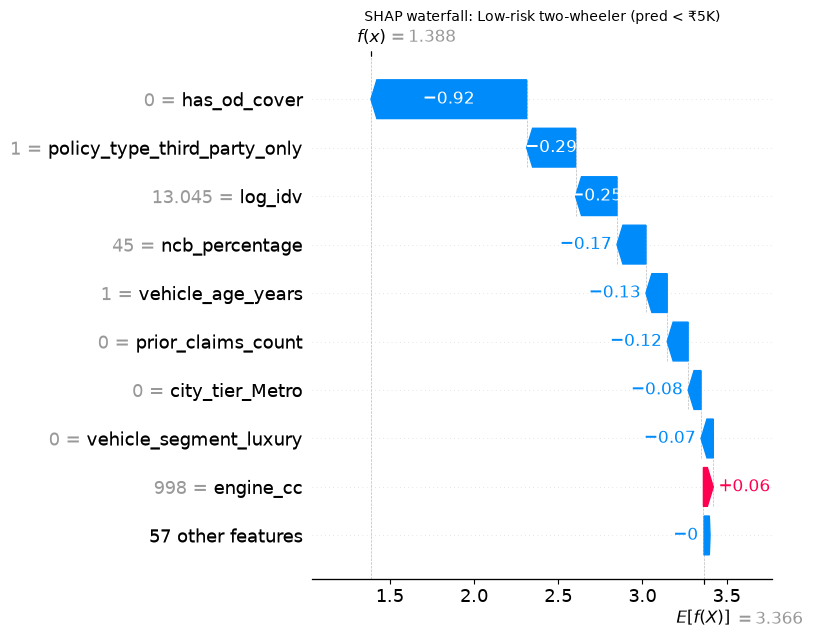

  Low-risk two-wheeler (pred < ₹5K): pred ₹4K  actual ₹0K


In [6]:
print("SECTION 4 — SHAP ON THE PRIMARY MODEL (Tweedie LightGBM)\n")
print("Computing SHAP values on 1,000 test policies — takes ~1 minute...")

X_te_df  = pd.DataFrame(
    test.merge(
        pd.read_csv(f"{PROCESSED}/modeling_data.csv")[["policy_id"] + FEATURES],
        on="policy_id", validate="1:1"
    )[FEATURES].to_numpy(float),
    columns=FEATURES
)

sample_idx = X_te_df.sample(1000, random_state=SEED).index
X_sample   = X_te_df.iloc[sample_idx]
y_sample   = y_te[sample_idx]

explainer  = shap.TreeExplainer(gbm)
shap_vals  = explainer.shap_values(X_sample)

mean_shap = pd.Series(
    np.abs(shap_vals).mean(axis=0),
    index=FEATURES
).sort_values(ascending=False)

print(f"\nTop 15 features by mean |SHAP| (model output is log ₹/₹1,000):")
print(f"  {'Rank':<5} {'Feature':<32} {'Mean |SHAP|':>12}")
print("-" * 52)
for i, (f, v) in enumerate(mean_shap.head(15).items(), 1):
    bar = "█" * int(v * 80)
    print(f"  {i:<5} {f:<32} {v:>12.4f}  {bar}")

print(f"\n  log_idv alone accounts for "
      f"{mean_shap['log_idv'] / mean_shap.sum() * 100:.1f}% of total mean |SHAP|")
print(f"  LightGBM gain share was 54.5% (SHAP and gain are different measures;")
print(f"  agreement strengthens the conclusion that IDV dominates)")

# Beeswarm
fig, ax = plt.subplots(figsize=(10, 9))
shap.summary_plot(shap_vals, X_sample, show=False, max_display=15)
plt.title("SHAP beeswarm — Tweedie LightGBM\n"
          "(red=high feature value pushes predicted cost up)", fontsize=11)
plt.tight_layout()
plt.savefig(f"{PROCESSED}/eval_02_shap_beeswarm.png",
            dpi=130, bbox_inches="tight")
plt.show()

# Three individual waterfall explanations
y_pred_sample = test["pred_gbm"].to_numpy()[sample_idx]
base_val      = explainer.expected_value

scenarios = {
    "High-risk luxury vehicle (pred > ₹500K)":
        np.where(y_pred_sample > 500_000)[0],
    "Typical economy policy (₹20K-₹80K predicted)":
        np.where((y_pred_sample >= 20_000) & (y_pred_sample <= 80_000))[0],
    "Low-risk two-wheeler (pred < ₹5K)":
        np.where(y_pred_sample < 5_000)[0],
}

for title, indices in scenarios.items():
    if len(indices) == 0:
        print(f"No example for: {title}")
        continue
    idx = indices[0]
    exp = shap.Explanation(
        values=shap_vals[idx],
        base_values=base_val,
        data=X_sample.iloc[idx],
        feature_names=FEATURES)
    fig, ax = plt.subplots(figsize=(10, 6))
    shap.plots.waterfall(exp, max_display=10, show=False)
    plt.title(f"SHAP waterfall: {title}", fontsize=10)
    plt.tight_layout()
    safe_title = "".join(c if c.isalnum() or c in "-_" else "_" for c in title).strip("_")
    plt.savefig(f"{PROCESSED}/eval_03_shap_{safe_title}.png",
                dpi=130, bbox_inches="tight")
    plt.show()
    pred_k = y_pred_sample[idx] / 1000
    act_k  = y_sample[idx] / 1000
    print(f"  {title}: pred ₹{pred_k:.0f}K  actual ₹{act_k:.0f}K")

In [7]:
print("SECTION 5 — GLM RATING RELATIVITIES\n")
print("""
The GLM is tied with LightGBM on Gini and has better balance (0.973).
Its log-link coefficients are multiplicative: exp(coef * sd(feature))
is the relativity applied to the base rate when the feature is one
standard deviation above its mean.

This is what IRDAI requires insurers to show: a table that says
'a taxi costs 1.14x the base' or 'NCB of 50 costs 0.89x the base'.
LightGBM cannot produce this directly; hence the GLM's value.
""")

from sklearn.preprocessing import StandardScaler
scaler = glm[0]  # StandardScaler is step 0 of the pipeline
coefs  = glm[-1].coef_
sds    = scaler.scale_

rels = pd.DataFrame({
    "feature" : FEATURES,
    "coef"    : coefs,
    "sd"      : sds,
    "relativity": np.exp(coefs),
}).sort_values("relativity", ascending=False)

# Keep only non-trivial effects
sig = rels[(rels["relativity"] > 1.03) | (rels["relativity"] < 0.97)]
print(f"Features with relativity outside [0.97, 1.03]  "
      f"({len(sig)} of {len(rels)}):\n")
print(f"  {'Feature':<32} {'Relativity':>11}  Interpretation")
for _, r in sig.iterrows():
    direction = "more expensive" if r["relativity"] > 1 else "cheaper"
    print(f"  {r['feature']:<32} x{r['relativity']:>8.3f}  {direction}")

print("""
How to read these:
  'relativity' is the multiplicative factor applied to the base
  expected claim cost when this feature is at its mean + 1 SD.
  For binary features (0/1), it is the multiplier for the class=1 group.
  The collinear one-hot columns within vehicle_segment and policy_type
  should be read relative to each other, not against the base rate.
""")

SECTION 5 — GLM RATING RELATIVITIES


The GLM is tied with LightGBM on Gini and has better balance (0.973).
Its log-link coefficients are multiplicative: exp(coef * sd(feature))
is the relativity applied to the base rate when the feature is one
standard deviation above its mean.

This is what IRDAI requires insurers to show: a table that says
'a taxi costs 1.14x the base' or 'NCB of 50 costs 0.89x the base'.
LightGBM cannot produce this directly; hence the GLM's value.

Features with relativity outside [0.97, 1.03]  (28 of 66):

  Feature                           Relativity  Interpretation
  log_idv                          x   2.254  more expensive
  has_od_cover                     x   1.293  more expensive
  policy_type_comprehensive        x   1.224  more expensive
  prior_claims_count               x   1.169  more expensive
  vehicle_type_taxi                x   1.143  more expensive
  vehicle_type_commercial_vehicle  x   1.120  more expensive
  is_young_driver                  x

In [8]:
print("SECTION 6 — PRICING SIMULATION\n")
print("""
Scenario: the insurer charges 120% of predicted cost as the premium
(20% loading for expenses and profit).

We compare this to the current premium on three metrics:
  1. Loss ratio by segment: are cross-subsidies reduced?
  2. Premium change for specific customer types
  3. How much the insurer's loss ratio would improve
     if 20% of the most overcharged customers switched to a competitor
""")

test_sim = test.copy()
test_sim["model_premium"] = test_sim["pred_glm"] * 1.20

# Loss ratios by policy type: current vs model
pt = test.merge(
    pd.read_csv(f"{PROCESSED}/policies_clean.csv",
                usecols=["policy_id","policy_type"]),
    on="policy_id")

print("Loss ratio by policy type — current premium vs model premium:")
print(f"  {'Policy type':<22} {'Curr LR':>9} {'Model LR':>10} "
      f"{'Curr overpay':>14} {'Model overpay':>14}")
for ptype in ["comprehensive", "standalone_od", "third_party_only"]:
    m = pt["policy_type"] == ptype
    actual   = pt.loc[m, "claim_amount"].sum()
    curr_p   = (k_prem * pt.loc[m, "total_premium"]).sum()
    model_p  = (pt.loc[m, "pred_glm"] * 1.20).sum()
    curr_lr  = actual / curr_p * 100
    model_lr = actual / model_p * 100
    overpay_curr  = (curr_p - actual) / actual * 100
    overpay_model = (model_p - actual) / actual * 100
    print(f"  {ptype:<22} {curr_lr:>8.1f}% {model_lr:>9.1f}% "
          f"{overpay_curr:>+13.1f}% {overpay_model:>+13.1f}%")

# Adverse selection simulation
print("\nAdverse selection — if the 20% most overcharged customers leave:")
print("(those whose current premium / model premium is highest = overcharged)")
test_sim2 = test_sim.copy()
test_sim2["overcharge_ratio"] = (
    k_prem * test_sim2["total_premium"]) / test_sim2["pred_glm"]
leave_mask = test_sim2["overcharge_ratio"] > test_sim2["overcharge_ratio"].quantile(0.80)
stay_mask  = ~leave_mask

for label, mask in [("Full portfolio", pd.Series([True]*len(test_sim2))),
                    ("After departures (20% most overcharged leave)", stay_mask)]:
    actual = test_sim2.loc[mask, "claim_amount"].sum()
    prem   = (k_prem * test_sim2.loc[mask, "total_premium"]).sum()
    lr     = actual / prem * 100
    n      = mask.sum()
    print(f"  {label[:45]:<45} n={n:>7,}  LR={lr:>6.1f}%")

print("""
Reading: 'adverse selection' is the dynamic where price-conscious
customers leave if they are overcharged. They tend to be good risks
(low claim rate, hence they attract competitor offers). What remains
is a worse-than-average pool — the loss ratio rises for the insurer.
A correctly priced portfolio avoids this spiral.
""")

SECTION 6 — PRICING SIMULATION


Scenario: the insurer charges 120% of predicted cost as the premium
(20% loading for expenses and profit).

We compare this to the current premium on three metrics:
  1. Loss ratio by segment: are cross-subsidies reduced?
  2. Premium change for specific customer types
  3. How much the insurer's loss ratio would improve
     if 20% of the most overcharged customers switched to a competitor

Loss ratio by policy type — current premium vs model premium:
  Policy type              Curr LR   Model LR   Curr overpay  Model overpay
  comprehensive             130.2%      83.3%         -23.2%         +20.0%
  standalone_od             149.2%      92.5%         -33.0%          +8.1%
  third_party_only           37.6%     104.4%        +165.9%          -4.2%

Adverse selection — if the 20% most overcharged customers leave:
(those whose current premium / model premium is highest = overcharged)
  Full portfolio                                n= 19,596  LR= 106.1%

In [9]:
print("=" * 70)
print(" INSURANCE CLAIM PREDICTION — COMPLETE EVALUATION SUMMARY")
print("=" * 70)

sb = pd.DataFrame(summary["scoreboard"]).set_index("model")
fa = summary["frequency_auc"]

print(f"""
DATASET
  Policies          : 97,978
  Claim rate        : 36.49%
  Target            : zero-inflated (63.5% zeros) + right-skewed positives
  Tweedie power p   : {summary['tweedie_power']} (not identified by CV — all powers in 1-2 tied)

SCOREBOARD (test set, 19,596 policies)
  {'Model':<30} {'Norm Gini':>10} {'Deviance':>10} {'Balance':>9}
  {'-'*62}""")
for nm, r in sb.iterrows():
    mark = "  <- primary" if nm == "Tweedie LightGBM" else ""
    print(f"  {nm:<30} {r['norm_gini']:>10.4f} {r['deviance']:>10.3f} "
          f"{r['balance']:>9.3f}{mark}")

print(f"""
GAIN ATTRIBUTION
  Total gain over premium     : +0.0515 Gini points
  From IDV + policy-type fix  : +0.0280  ({0.0280/0.0515*100:.0f}% of total)
  From all other features     : +0.0235  ({0.0235/0.0515*100:.0f}% of total)
  Conclusion: more than half the gain is a pricing correction that a
  single underwriting rule could replicate, not a novel ML discovery.

FREQUENCY
  Model AUC : {fa['model']:.4f}
  Oracle AUC: {fa['oracle']:.4f}
  Almost at the ceiling. The generator's claim probability is nearly
  recovered by the model.

SEVERITY
  Gamma deviance explained vs constant : 17.41%
  Spearman(predicted, actual)          : 0.4528
  Hard problem: claim type is unknown at quote time. A mixture of
  theft (median 71% of IDV) and own damage (median 5% of IDV) in the
  same target creates irreducible noise in any quote-time model.
""")

print("=" * 70)
print(" CONFIRMED GENERATOR LIMITATIONS (for README)")
print("=" * 70)
print("""
All six were identified from the code and confirmed by data:

1. LOSS RATIO ~407%
   Cause: severity multipliers produce absolute amounts that
   exceed a realistic multiple of premium. Feature RELATIONSHIPS
   are correctly encoded; the absolute scale is not.

2. MONSOON EFFECT IN SEVERITY ONLY
   Confirmed: Jul-Sep claim share 25.2% (flat); median claim/IDV
   1.46x the rest. Real portfolios show higher frequency too.

3. THIRD-PARTY SEVERITY MULTIPLIER UNUSED
   Confirmed: median claim/IDV for third_party and own_damage on
   comprehensive policies are almost identical (0.088 vs 0.087).
   Third-party liability does not scale with the insured vehicle's
   value in reality.

4. TP-ONLY POLICIES CARRY OWN-DAMAGE CLAIMS
   Confirmed: 74.9% of claims on TP-only policies are non-TP types.
   In real motor insurance this is contractually impossible.

5. TP-ONLY POLICIES CHARGED OWN-DAMAGE PREMIUM
   Confirmed: TP-only rel LR = 0.33 (hugely overcharged vs portfolio).
   The generator computes the OD component for every policy type.

6. MISSING VEHICLE AGE INFLATES IDV
   Confirmed: missing-age rows show median IDV 1.55x the make's median
   (hypothesis from code: NaN age => 0% depreciation => new-car IDV).
   Affects 1,979 of 97,978 policies (2.0%).

WHAT THESE MEAN FOR THE ML RESULTS
  Limitation 4 and 5 together are why IDV + policy type scores 0.7193:
  ML learned that TP-only policies are cheap, which they are in this
  simulation. A real insurer already knows this from the rating structure.
  Limitation 6 affects IDV for 2% of rows; Cell 3 checks whether the
  artifact-free subset changes the conclusions.
""")

# Save the evaluation summary for the README
eval_out = {
    "scoreboard"          : summary["scoreboard"],
    "gain_attribution"    : {
        "premium_baseline": 0.6913, "idv_policy_type": 0.7193,
        "full_model": float(sb.loc["Tweedie LightGBM","norm_gini"]),
        "pct_from_pricing_fix": round(0.0280/0.0515*100, 1),
        "pct_from_other_features": round(0.0235/0.0515*100, 1),
    },
    "frequency_auc"       : fa,
    "severity"            : {"deviance_explained": 0.1741, "spearman": 0.4528},
    "tweedie_power"       : P_FINAL,
    "n_limitations"       : 6,
}
with open(f"{PROCESSED}/eval_summary.json", "w") as f:
    json.dump(eval_out, f, indent=2)
print("✅ eval_summary.json saved")

 INSURANCE CLAIM PREDICTION — COMPLETE EVALUATION SUMMARY

DATASET
  Policies          : 97,978
  Claim rate        : 36.49%
  Target            : zero-inflated (63.5% zeros) + right-skewed positives
  Tweedie power p   : 1.67 (not identified by CV — all powers in 1-2 tied)

SCOREBOARD (test set, 19,596 policies)
  Model                           Norm Gini   Deviance   Balance
  --------------------------------------------------------------
  Premium (scaled)                   0.6913     19.166     0.942
  IDV only (scaled)                  0.6727     19.411     0.940
  Tweedie GLM                        0.7443     17.291     0.973
  Tweedie LightGBM                   0.7428     17.361     0.893  <- primary
  Two-part LightGBM                  0.7449     17.299     0.899
  Ref: true P(claim) x model severity     0.7469     17.247     0.899

GAIN ATTRIBUTION
  Total gain over premium     : +0.0515 Gini points
  From IDV + policy-type fix  : +0.0280  (54% of total)
  From all other featu